<a href="https://colab.research.google.com/github/himanshukumar1500/Neural_Networks_and_Deep_Learning/blob/main/FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Practical-7: FashionMNIST Classification with pyTorch

##Aim:
1. Find the final model size and number of parameters.



2. Improve accuracy by tuning different hyperparameters.



3. Implement One-vs-All
classification and compare it with multiclass classification.



##Load the dataset and import libraries
 To load the FashionMNIST dataset and prepare it for training.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Convert images into tensors
transform = transforms.ToTensor()

# Load FashionMNIST dataset
train_dataset = datasets.FashionMNIST(
    root="./data", train=True, download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data", train=False, download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=512, shuffle=False
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)

Using device: cpu


100%|██████████| 26.4M/26.4M [00:01<00:00, 18.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 280kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.10MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.5MB/s]

Training samples: 60000
Testing samples: 10000
Image shape: torch.Size([1, 28, 28])


##Display sample images

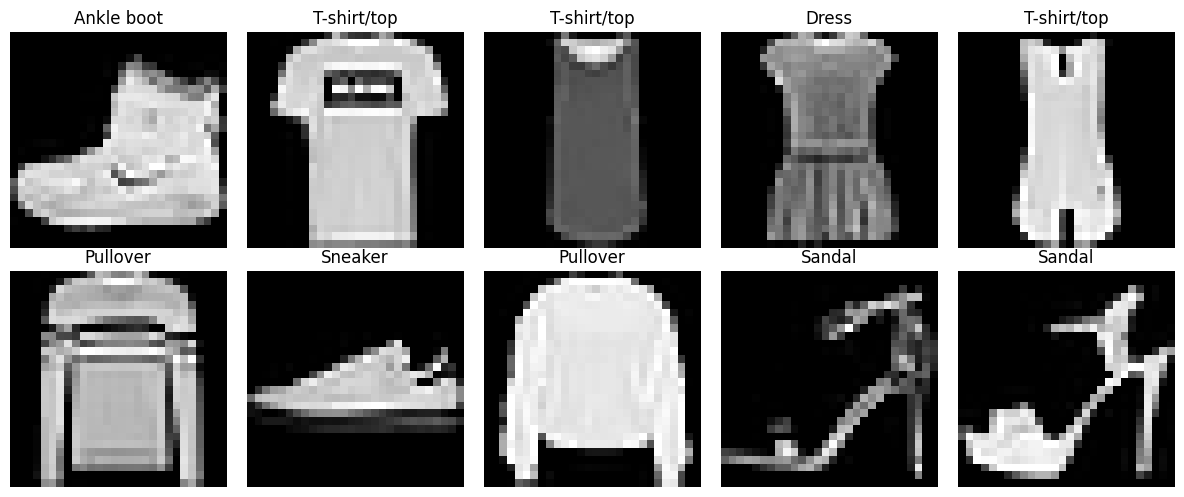

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

###Observation:
Each image is a grayscale image of size \(28 \times 28\) pixels. The dataset contains 10 clothing categories.

##Build and train the neural network
The model contains an input layer, two hidden layers, and an output layer with 10 neurons.

In [4]:
# Define the neural network
class FashionMNISTModel(nn.Module):
    def __init__(self, hidden1=256, hidden2=128, dropout=0.2):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden2, 10)
        )

    def forward(self, x):
        return self.network(x)


model = FashionMNISTModel().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

FashionMNISTModel(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)


##Training and testing functions

In [5]:
def train_model(model, train_loader, test_loader,
                epochs=5, lr=0.001, optimizer_name="Adam"):

    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "SGD":
        optimizer = optim.SGD(
            model.parameters(), lr=lr, momentum=0.9
        )
    else:
        optimizer = optim.Adam(
            model.parameters(), lr=lr
        )

    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # Test accuracy
        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                predictions = outputs.argmax(dim=1)

                total += labels.size(0)
                correct += (predictions == labels).sum().item()

        accuracy = 100 * correct / total
        avg_loss = total_loss / len(train_loader)

        history.append(accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {avg_loss:.4f} "
            f"Test Accuracy: {accuracy:.2f}%"
        )

    return history


history = train_model(
    model, train_loader, test_loader,
    epochs=5, lr=0.001
)

Epoch [1/5] Loss: 0.6118 Test Accuracy: 83.77%
Epoch [2/5] Loss: 0.4100 Test Accuracy: 85.34%
Epoch [3/5] Loss: 0.3700 Test Accuracy: 85.97%
Epoch [4/5] Loss: 0.3480 Test Accuracy: 86.62%
Epoch [5/5] Loss: 0.3300 Test Accuracy: 87.21%


##Ploting the accuracy

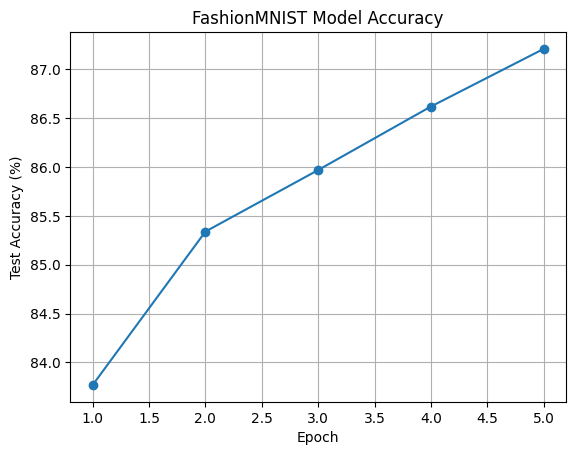

In [6]:
plt.plot(range(1, len(history) + 1), history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("FashionMNIST Model Accuracy")
plt.grid(True)
plt.show()

##Finding the final model size
 To calculate the total trainable parameters and estimate the model size.

In [7]:
# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# Calculate parameter memory
parameter_bytes = sum(
    p.numel() * p.element_size()
    for p in model.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_params)
print("Parameter memory in MB:", parameter_bytes / 1_000_000)

# Save the trained model
torch.save(model.state_dict(), "fashion_mnist_model.pth")

import os

file_size = os.path.getsize("fashion_mnist_model.pth")

print("Saved model size in MB:", file_size / 1_000_000)

Total trainable parameters: 235146
Parameter memory in MB: 0.940584
Saved model size in MB: 0.943909


##Improving accuracy using hyperparameter tuning
I experimented with different learning rates, batch sizes, hidden-layer sizes, dropout values, and optimizers to find a better-performing model.

In [8]:
experiments = [
    {"lr": 0.001, "batch": 128, "hidden": 256,
     "dropout": 0.2, "optimizer": "Adam"},

    {"lr": 0.0003, "batch": 128, "hidden": 256,
     "dropout": 0.2, "optimizer": "Adam"},

    {"lr": 0.003, "batch": 128, "hidden": 256,
     "dropout": 0.2, "optimizer": "Adam"},

    {"lr": 0.001, "batch": 128, "hidden": 512,
     "dropout": 0.3, "optimizer": "Adam"},

    {"lr": 0.01, "batch": 128, "hidden": 256,
     "dropout": 0.2, "optimizer": "SGD"}
]

results = []

for exp in experiments:
    print("\nExperiment:", exp)

    # Change batch size
    train_dl = DataLoader(
        train_dataset,
        batch_size=exp["batch"],
        shuffle=True
    )

    test_dl = DataLoader(
        test_dataset,
        batch_size=512,
        shuffle=False
    )

    # Create model with selected hyperparameters
    tuned_model = FashionMNISTModel(
        hidden1=exp["hidden"],
        hidden2=128,
        dropout=exp["dropout"]
    ).to(device)

    acc_history = train_model(
        tuned_model,
        train_dl,
        test_dl,
        epochs=3,
        lr=exp["lr"],
        optimizer_name=exp["optimizer"]
    )

    results.append({
        "Learning Rate": exp["lr"],
        "Batch Size": exp["batch"],
        "Hidden Layer": exp["hidden"],
        "Dropout": exp["dropout"],
        "Optimizer": exp["optimizer"],
        "Accuracy (%)": round(acc_history[-1], 2)
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("Accuracy (%)", ascending=False))


Experiment: {'lr': 0.001, 'batch': 128, 'hidden': 256, 'dropout': 0.2, 'optimizer': 'Adam'}
Epoch [1/3] Loss: 0.6124 Test Accuracy: 83.83%
Epoch [2/3] Loss: 0.4110 Test Accuracy: 85.92%
Epoch [3/3] Loss: 0.3717 Test Accuracy: 86.81%

Experiment: {'lr': 0.0003, 'batch': 128, 'hidden': 256, 'dropout': 0.2, 'optimizer': 'Adam'}
Epoch [1/3] Loss: 0.7826 Test Accuracy: 81.34%
Epoch [2/3] Loss: 0.4747 Test Accuracy: 84.50%
Epoch [3/3] Loss: 0.4153 Test Accuracy: 85.31%

Experiment: {'lr': 0.003, 'batch': 128, 'hidden': 256, 'dropout': 0.2, 'optimizer': 'Adam'}
Epoch [1/3] Loss: 0.5478 Test Accuracy: 84.63%
Epoch [2/3] Loss: 0.4162 Test Accuracy: 85.65%
Epoch [3/3] Loss: 0.3813 Test Accuracy: 85.55%

Experiment: {'lr': 0.001, 'batch': 128, 'hidden': 512, 'dropout': 0.3, 'optimizer': 'Adam'}
Epoch [1/3] Loss: 0.5978 Test Accuracy: 84.35%
Epoch [2/3] Loss: 0.4165 Test Accuracy: 85.02%
Epoch [3/3] Loss: 0.3751 Test Accuracy: 86.14%

Experiment: {'lr': 0.01, 'batch': 128, 'hidden': 256, 'dropout

,Learning Rate,Batch Size,Hidden Layer,Dropout,Optimizer,Accuracy (%)
0,0.0010,128,256,0.2,Adam,86.81
3,0.0010,128,512,0.3,Adam,86.14
2,0.0030,128,256,0.2,Adam,85.55
1,0.0003,128,256,0.2,Adam,85.31
4,0.0100,128,256,0.2,SGD,84.20


##Comparing the results graphically

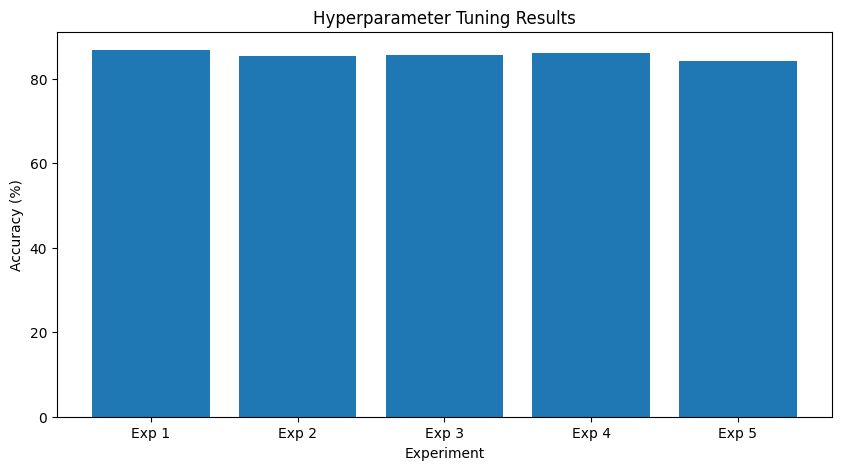

Best experiment:


,0
Learning Rate,0.001
Batch Size,128
Hidden Layer,256
Dropout,0.2
Optimizer,Adam
Accuracy (%),86.81


In [9]:
plt.figure(figsize=(10, 5))

plt.bar(
    range(len(results_df)),
    results_df["Accuracy (%)"]
)

plt.xticks(
    range(len(results_df)),
    [f"Exp {i+1}" for i in range(len(results_df))]
)

plt.xlabel("Experiment")
plt.ylabel("Accuracy (%)")
plt.title("Hyperparameter Tuning Results")
plt.show()

print("Best experiment:")
display(results_df.loc[results_df["Accuracy (%)"].idxmax()])

Observation: Changing the learning rate, batch size, hidden-layer size, dropout, and optimizer affects the model's accuracy. The best configuration is the one with the highest measured accuracy in the results table. For a rigorous experiment, select hyperparameters using a validation set and evaluate the final model once on the test set.

##Implementing One-vs-All classification
In One-vs-All (OvA), I train 10 separate binary classifiers. Each classifier learns to identify one clothing class against all the other classes.

In [10]:
class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


def train_binary_classifier(class_id, epochs=3):
    binary_model = BinaryClassifier().to(device)

    optimizer = optim.Adam(
        binary_model.parameters(), lr=0.001
    )

    criterion = nn.BCEWithLogitsLoss()

    for epoch in range(epochs):
        binary_model.train()

        for images, labels in train_loader:
            images = images.to(device)

            # Positive for the selected class, negative otherwise
            binary_labels = (
                labels == class_id
            ).float().to(device)

            optimizer.zero_grad()

            outputs = binary_model(images)
            loss = criterion(outputs, binary_labels)

            loss.backward()
            optimizer.step()

        print(
            f"Class {class_id}: "
            f"Epoch {epoch+1}/{epochs}, "
            f"Loss = {loss.item():.4f}"
        )

    return binary_model


# Train 10 binary classifiers
ova_models = []

for class_id in range(10):
    print("\nTraining:", class_names[class_id])

    binary_model = train_binary_classifier(
        class_id, epochs=3
    )

    ova_models.append(binary_model)

print("All 10 One-vs-All classifiers trained.")


Training: T-shirt/top
Class 0: Epoch 1/3, Loss = 0.1307
Class 0: Epoch 2/3, Loss = 0.0981
Class 0: Epoch 3/3, Loss = 0.0439

Training: Trouser
Class 1: Epoch 1/3, Loss = 0.0061
Class 1: Epoch 2/3, Loss = 0.0083
Class 1: Epoch 3/3, Loss = 0.0032

Training: Pullover
Class 2: Epoch 1/3, Loss = 0.1486
Class 2: Epoch 2/3, Loss = 0.1967
Class 2: Epoch 3/3, Loss = 0.0662

Training: Dress
Class 3: Epoch 1/3, Loss = 0.1181
Class 3: Epoch 2/3, Loss = 0.0579
Class 3: Epoch 3/3, Loss = 0.0933

Training: Coat
Class 4: Epoch 1/3, Loss = 0.1126
Class 4: Epoch 2/3, Loss = 0.1110
Class 4: Epoch 3/3, Loss = 0.0986

Training: Sandal
Class 5: Epoch 1/3, Loss = 0.1056
Class 5: Epoch 2/3, Loss = 0.0339
Class 5: Epoch 3/3, Loss = 0.0568

Training: Shirt
Class 6: Epoch 1/3, Loss = 0.1631
Class 6: Epoch 2/3, Loss = 0.2429
Class 6: Epoch 3/3, Loss = 0.1063

Training: Sneaker
Class 7: Epoch 1/3, Loss = 0.0176
Class 7: Epoch 2/3, Loss = 0.0057
Class 7: Epoch 3/3, Loss = 0.0063

Training: Bag
Class 8: Epoch 1/3, 

##Test One-vs-All accuracy

In [12]:
def evaluate_ova(models, loader):
    for m in models:
        m.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            # Obtain one score from each classifier
            scores = torch.stack(
                [m(images) for m in models],
                dim=1
            )

            # Select the class with the highest score
            predictions = scores.argmax(dim=1)

            total += labels.size(0)
            correct += (
                predictions == labels
            ).sum().item()

    return 100 * correct / total


ova_accuracy = evaluate_ova(ova_models, test_loader)

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        predictions = model(images).argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

multiclass_accuracy = 100 * correct / total

print(f"Multiclass accuracy: {multiclass_accuracy:.2f}%")
print(f"One-vs-All accuracy: {ova_accuracy:.2f}%")

Multiclass accuracy: 87.21%
One-vs-All accuracy: 86.89%


##Now Comparing both classification methods

,Classification Method,Test Accuracy (%)
0,Multiclass,87.21
1,One-vs-All,86.89


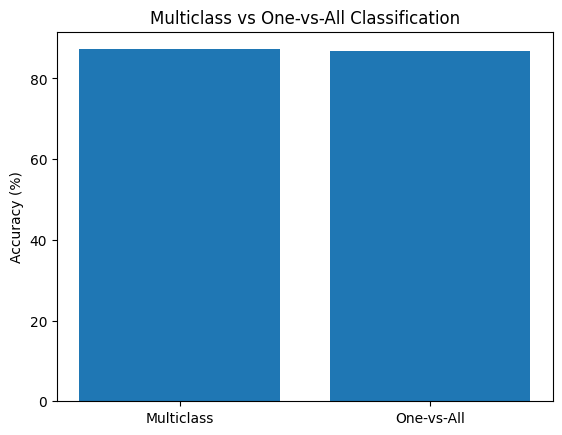

In [13]:
comparison = pd.DataFrame({
    "Classification Method": [
        "Multiclass",
        "One-vs-All"
    ],
    "Test Accuracy (%)": [
        multiclass_accuracy,
        ova_accuracy
    ]
})

display(comparison)

plt.bar(
    comparison["Classification Method"],
    comparison["Test Accuracy (%)"]
)

plt.ylabel("Accuracy (%)")
plt.title("Multiclass vs One-vs-All Classification")
plt.show()

Conclusion: I implemented a PyTorch neural network for FashionMNIST classification, calculated its model size, experimented with different hyperparameters, and implemented One-vs-All classification. I compared the test accuracies of both approaches to understand their performance.